# 01 · Can we trust the data?

Before analysing anything, I want to be sure of four things, because every result depends on them:

1. The files I'm using are exactly the ones in the `data.zip` we were given.
2. Every value reads correctly: dates as dates, amounts as numbers, nothing lost on the way in.
3. Every record points to something real. A quote belongs to a real customer of the same business,
   a job to a real property, and so on.
4. My counts of quotes match the counts the platform keeps separately.

In [1]:
import sys

sys.path.insert(0, "../scripts")

import pandas as pd
from IPython.display import Image, display

from quote_followup.config import load_settings
from quote_followup.data import load_quotes

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 100)
settings = load_settings("../config.toml")
quotes = load_quotes(settings.data_dir)

import os
from pathlib import Path

import explore

from quote_followup import audit

## How the tables connect

This is the diagram that came with the data. Each business has its own customers, and everything
below them belongs to that same business. When I check a link, I check it within the business, so a
quote attached to another business's customer counts as broken.

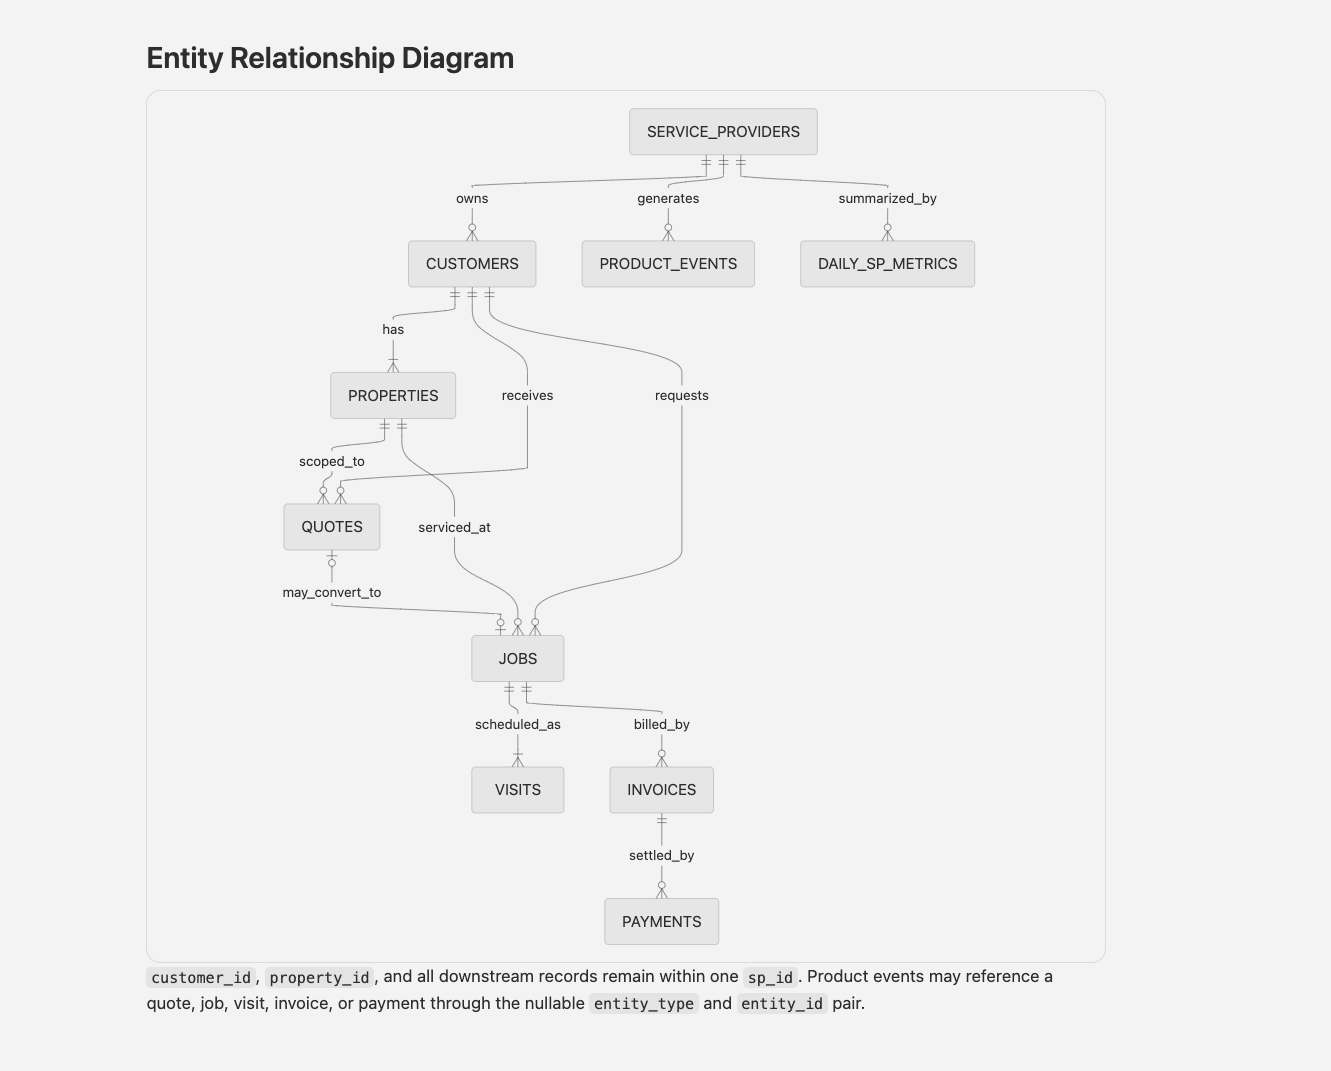

In [2]:
display(Image("../reference/ERD.png", width=640))

## Running every check

One row per check. `ok` is True when it passes.

In [3]:
supplied_zip = Path(os.environ.get("DATA_ZIP", "../../data.zip"))
report = audit.run(settings.data_dir, Path("../reference/DATA_DICTIONARY.csv"), quotes, supplied_zip)
report.groupby("check", sort=False)["ok"].agg(checks="size", passed="sum")

,checks,passed
check,,
matches zip,10,10
row count,10,10
columns,10,10
types parse,10,10
required present,10,10
key unique,10,10
links,16,16
quote rule,6,6
reconciles,4,4


Every check passes. The two groups worth reading in full are the links between tables and the cross-checks against the platform's own counts.

In [4]:
report[report["check"].isin(["links", "reconciles"])]

,check,table,detail,ok
60,links,customers,sp_id -> service_providers: 0 orphans,True
61,links,properties,customer_id+sp_id -> customers: 0 orphans,True
62,links,quotes,customer_id+sp_id -> customers: 0 orphans,True
63,links,quotes,property_id+customer_id+sp_id -> properties: 0 orphans,True
64,links,jobs,property_id+customer_id+sp_id -> properties: 0 orphans,True
65,links,jobs,quote_id+customer_id+sp_id -> quotes: 0 orphans,True
66,links,visits,job_id+customer_id+property_id+sp_id -> jobs: 0 orphans,True
67,links,invoices,job_id+customer_id+property_id+sp_id -> jobs: 0 orphans,True
68,links,payments,invoice_id+customer_id+sp_id -> invoices: 0 orphans,True
69,links,product_events,sp_id -> service_providers: 0 orphans,True


The cross-checks are the strongest evidence that I'm reading the quotes correctly.
`daily_sp_metrics` is a separate summary the platform keeps of how many quotes each business
created, sent and had accepted each day. Counting the same things from the quotes table gives
exactly the same numbers on every business-day. It also confirms what the `decided_at` column means,
since the platform counts an acceptance on that date.

## How the quotes are read

Every column is read as plain text first, then dates are converted using the exact format in the
files (like `2024-05-15T10:20:00`). Anything that doesn't fit stops the run, instead of slipping
through as a blank.

In [5]:
quotes.head(3).T

,0,1,2
quote_id,QU020966,QU009646,QU009494
sp_id,SP0418,SP0198,SP0196
customer_id,CU009997,CU004785,CU004725
property_id,PR009997,PR004785,PR004725
workflow_type,recurring,emergency,recurring
created_at,2024-01-01 08:06:00,2024-01-01 10:15:00,2024-01-01 10:16:00
sent_at,2024-01-01 09:06:00,2024-01-01 12:15:00,2024-01-01 14:16:00
expires_at,2024-01-31 09:06:00,2024-01-31 12:15:00,2024-01-31 14:16:00
decided_at,2024-01-12 16:06:00,2024-01-03 16:15:00,2024-01-04 21:16:00
status,declined,accepted,accepted


## Preprocessing

Row count after each step.

In [6]:
import figures
import style

style.apply()
explore.preprocessing_steps(quotes)

,rows
step,
"read quotes.csv as text, parse dates and amounts strictly",25000
"join customer and business on (sp_id, customer_id); all match",25000
"derive won, hours_to_send, log(1 + hours), send_speed, days_to_decision",25000
"drop the 1,444 stale 'open' quotes from learning and scoring",23556
"learning set on 2024-09-01: sent 45+ days earlier, ending on record",9077
"in the model: one-hot encode work and source, standardise log hours",9077


## Missing values

Mostly by design: `cancelled_at` only exists for cancelled visits, `decline_reason` only for declines,
`subscription_end_at` only for businesses that left. The gaps that matter for quotes are handled
above: `decided_at` is empty for quotes that expired.

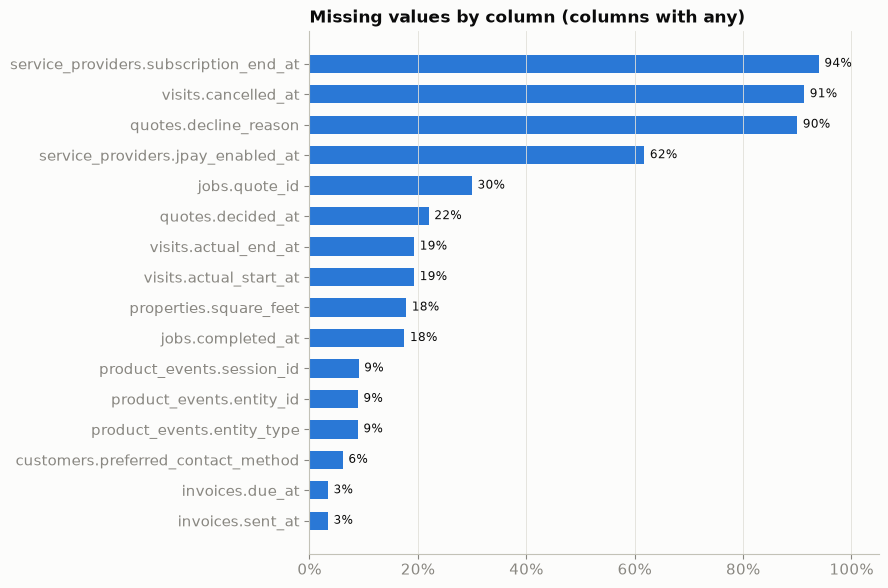

In [7]:
figures.eda_missing(settings.data_dir)

## Sending time on a log scale

Quotes go out in daily batches (same day, next day, two days later), and a few take a week. The log
brings the skew from 1.4 to −0.6, so one slow quote doesn't dominate the model.

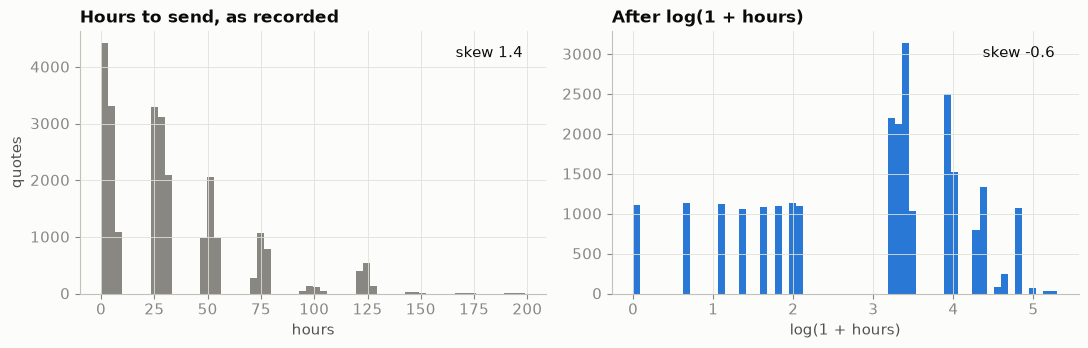

In [8]:
figures.eda_transform(quotes)

A few columns are worked out from the quote itself:

| column | what it means |
|---|---|
| `won` | 1 if accepted, 0 if declined or expired, blank for the 1,444 still marked "open" |
| `hours_to_send` | hours between writing the quote and sending it |
| `send_speed` | "within a day" or "after a day" |
| `resolved_at` | when the ending became known: the reply date, or the expiry date if nobody replied |
| `days_to_decision` | days between sending and the reply; blank if the quote expired |

## Facts that shaped the rest of the work

In [9]:
explore.data_facts(settings.data_dir, quotes)

latest payment or product event            19 Mar 2025
latest expiry date of any quote            23 Jan 2025
quotes still marked open                          1444
  of those, already past their expiry             100%
replies more than 45 days after sending              6
replies in total                                 19493
dtype: object

- **The "open" quotes aren't really open.** The data runs to 19 March 2025, and every quote had
  expired by 23 January. The 1,444 quotes still marked "open" aren't waiting for an answer; they
  look like a glitch in the export. I leave them out, and notebook 05 shows that counting them as
  lost changes nothing.
- **Waiting 45 days before learning from a quote loses almost nothing.** Only six replies ever
  came later than that.

In [10]:
explore.quote_value_check(settings.data_dir, quotes)

,planned value / quote,invoiced value / quote
work,,
emergency job,1.025,1.022
one-off project,1.025,1.024
recurring service,1.024,1.023


- **The quoted amount is a fair measure of what a win is worth.** For every type of work, the job
  that follows a won quote is planned and invoiced within a few percent of the quote.